# Benchmark Results

## 1. Setup

A run is one directory under `results/baselines/`. The files directly under `results/` are the Python engine measured with PyTorch's default thread count.

In [12]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

RESULTS = Path("../results")
RUNS = ["python-engine-and-cpp-network", "cpp-engine-sequential-search", "cpp-engine-batched-search-tuned-network"]
RUN_DIR = {run: RESULTS / "baselines" / run for run in RUNS}
LATEST = RUNS[-1]
DEFAULT_THREADS = "results/ (default threads)"

plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
    "font.size": 10,
})

RUN_COLOR = {"python-engine-and-cpp-network": "#b8c0cc", "cpp-engine-sequential-search": "#7fb7be", "cpp-engine-batched-search-tuned-network": "#e76f51"}
RUN_MARKER = {"python-engine-and-cpp-network": "o", "cpp-engine-sequential-search": "s", "cpp-engine-batched-search-tuned-network": "^"}
REGIONS = ["start", "mid", "end"]

VARIANTS = [
    ("torch_predict_default_threads", "PyTorch predict, default threads", "#9aa5b4"),
    ("torch_predict_1thread", "PyTorch predict, 1 thread", "#66748a"),
    ("torch_forward_1thread", "PyTorch forward, 1 thread", "#3f4b5e"),
    ("cpp_reference_fp32", "C++ plain loops, fp32", "#e5c07b"),
    ("cpp_reference_fp16", "C++ plain loops, fp16", "#d19a45"),
    ("cpp_avx2_fp32", "C++ AVX2, fp32", "#3aa89a"),
    ("cpp_avx2_fp16", "C++ AVX2, fp16", "#237a70"),
    ("cpp_avx2_fp32_batch4", "C++ AVX2, fp32, batch 4", "#ee7a5a"),
    ("cpp_avx2_fp16_batch4", "C++ AVX2, fp16, batch 4", "#c0513a"),
]
LABEL = {key: label for key, label, _ in VARIANTS}
COLOR = {key: color for key, _, color in VARIANTS}
ORDER = [key for key, _, _ in VARIANTS]

environments = {run: json.loads((RUN_DIR[run] / "environment.json").read_text()) for run in RUNS}
pd.DataFrame({
    run: {
        "timestamp": env["timestamp"],
        "cpu": env["cpu_model"],
        "pinned cpu": env["pinned_cpu"],
        "governor": env["governor"],
        "compiler": env["compiler"],
        "build type": env["cmake_build_type"],
        "torch": env["torch"],
    } for run, env in environments.items()
})

,python-engine-and-cpp-network,cpp-engine-sequential-search,cpp-engine-batched-search-tuned-network
timestamp,2026-10-06T12:19:51+05:00,2026-10-06T17:40:23+05:00,2026-10-08T00:09:35+05:00
cpu,13th Gen Intel(R) Core(TM) i9-13900HX,13th Gen Intel(R) Core(TM) i9-13900HX,13th Gen Intel(R) Core(TM) i9-13900HX
pinned cpu,8,8,8
governor,performance,performance,performance
compiler,g++ (Ubuntu 12.4.0-2ubuntu1~24.04.1) 12.4.0,g++ (Ubuntu 12.4.0-2ubuntu1~24.04.1) 12.4.0,g++ (Ubuntu 12.4.0-2ubuntu1~24.04.1) 12.4.0
build type,,,
torch,2.13.0+cpu,2.13.0+cpu,2.13.0+cpu


## 2. Run Inventory

Each column is a measurement. A check mark means the run holds it.

In [13]:
ENGINE_FOLDERS = ["python_engine", "cpp_engine", "cpp_batch4_engine"]
inventory = pd.DataFrame({
    run: {
        "network latency": (RUN_DIR[run] / "network.csv").exists(),
        "machine peaks": (RUN_DIR[run] / "peaks.json").exists(),
        "board rules": (RUN_DIR[run] / "rules.json").exists(),
        **{folder.removesuffix("_engine") + " search": (RUN_DIR[run] / folder / "move_selection.csv").exists() for folder in ENGINE_FOLDERS},
    } for run in RUNS
}).T.map(lambda present: "✓" if present else "")
inventory.loc[DEFAULT_THREADS] = ["", "", "", "✓", "", ""]
inventory

,network latency,machine peaks,board rules,python search,cpp search,cpp_batch4 search
python-engine-and-cpp-network,✓,✓,✓,✓,,
cpp-engine-sequential-search,✓,✓,✓,✓,✓,
cpp-engine-batched-search-tuned-network,✓,✓,✓,✓,✓,✓
results/ (default threads),,,,✓,,


## 3. Network Latency

Latency is the median time of one network evaluation per board over 30 repetitions. Bars show the quartile range. This section shows the latest run.

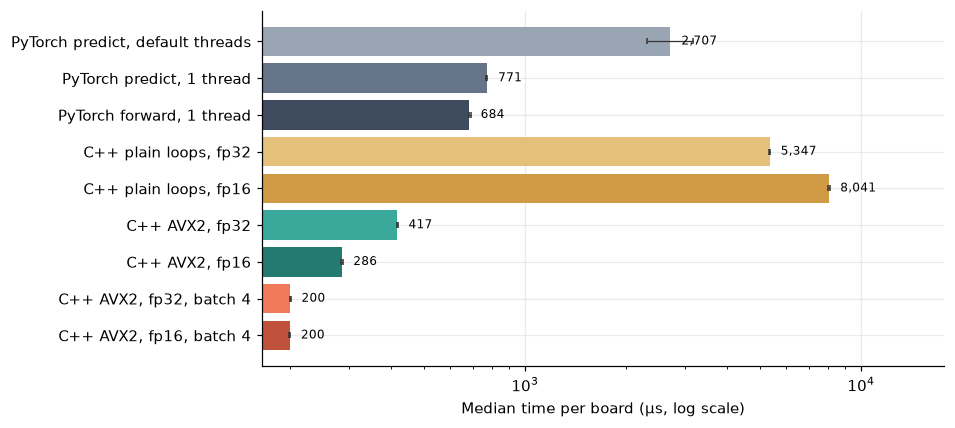

,median (µs),spread (cv %),"speedup vs PyTorch predict, 1 thread"
variant,,,
"PyTorch predict, default threads",2706.71,21.89,0.28
"PyTorch predict, 1 thread",771.28,1.25,1.00
"PyTorch forward, 1 thread",684.29,1.28,1.13
"C++ plain loops, fp32",5347.27,1.31,0.14
"C++ plain loops, fp16",8040.66,0.92,0.10
"C++ AVX2, fp32",417.46,1.89,1.85
"C++ AVX2, fp16",285.82,0.77,2.70
"C++ AVX2, fp32, batch 4",200.40,0.63,3.85
"C++ AVX2, fp16, batch 4",199.64,1.13,3.86


In [14]:
network = pd.read_csv(RUN_DIR[LATEST] / "network.csv").set_index("variant").loc[ORDER]
reference = network.loc["torch_predict_1thread", "median_ns"]
network["median_us"] = network["median_ns"] / 1e3
network["speedup_vs_torch_1thread"] = reference / network["median_ns"]

fig, ax = plt.subplots(figsize=(8, 4.2))
y = np.arange(len(network))[::-1]
lower = (network["median_ns"] - network["p25_ns"]) / 1e3
upper = (network["p75_ns"] - network["median_ns"]) / 1e3
ax.barh(y, network["median_us"], xerr=[lower, upper], color=[COLOR[v] for v in network.index],
        error_kw={"ecolor": "#333", "capsize": 2, "lw": 0.8})
ax.set_yticks(y, [LABEL[v] for v in network.index])
ax.set_xscale("log")
ax.set_xlabel("Median time per board (µs, log scale)")
for yi, v in zip(y, network["median_us"]):
    ax.text(v * 1.08, yi, f"{v:,.0f}", va="center", fontsize=8)
ax.set_xlim(right=network["median_us"].max() * 2.2)
plt.show()

network[["median_us", "cv_percent", "speedup_vs_torch_1thread"]].rename(
    index=LABEL, columns={"median_us": "median (µs)", "cv_percent": "spread (cv %)",
                          "speedup_vs_torch_1thread": "speedup vs PyTorch predict, 1 thread"}
).round(2)

## 4. Network Latency by Run

The table lists the median time per board of each variant in each run. The first column is the Python engine's CNN call in `results/flat_ops.csv`.

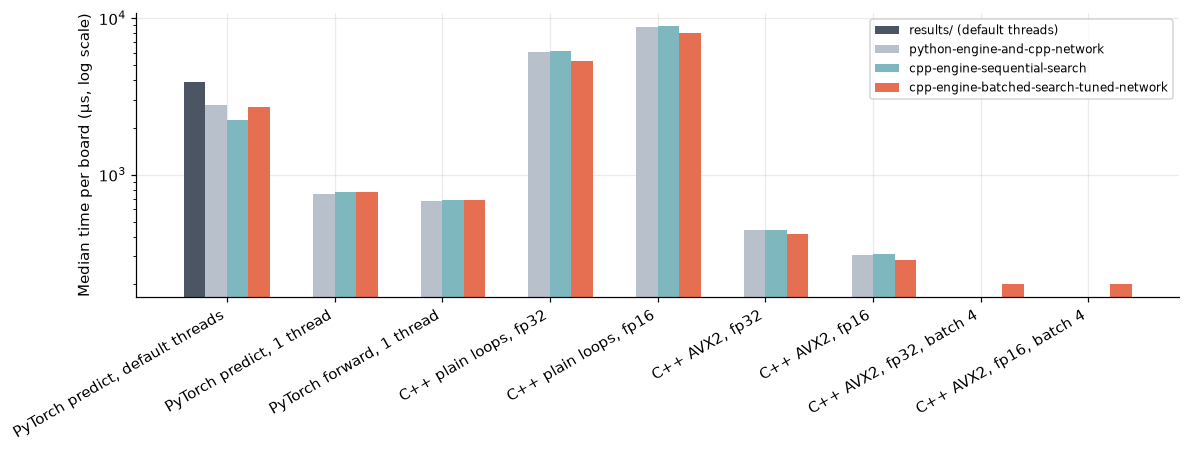

,results/ (default threads),python-engine-and-cpp-network,cpp-engine-sequential-search,cpp-engine-batched-search-tuned-network
variant,,,,
"PyTorch predict, default threads",3901.0,2787.4,2247.1,2706.7
"PyTorch predict, 1 thread",NaN,754.9,776.7,771.3
"PyTorch forward, 1 thread",NaN,681.1,690.5,684.3
"C++ plain loops, fp32",NaN,6107.6,6211.0,5347.3
"C++ plain loops, fp16",NaN,8741.2,8897.7,8040.7
"C++ AVX2, fp32",NaN,439.7,444.4,417.5
"C++ AVX2, fp16",NaN,306.2,310.4,285.8
"C++ AVX2, fp32, batch 4",NaN,NaN,NaN,200.4
"C++ AVX2, fp16, batch 4",NaN,NaN,NaN,199.6


In [15]:
networks = {run: pd.read_csv(RUN_DIR[run] / "network.csv").set_index("variant") for run in RUNS}
flat_ops = pd.read_csv(RESULTS / "flat_ops.csv").set_index("operation")
by_run = pd.DataFrame({run: df["median_ns"] / 1e3 for run, df in networks.items()}).reindex(ORDER)
by_run.insert(0, DEFAULT_THREADS, np.nan)
by_run.loc["torch_predict_default_threads", DEFAULT_THREADS] = flat_ops.loc["cnn_inference", "mean_ms"] * 1e3
by_run = by_run.dropna(how="all")

columns = list(by_run.columns)
width = 0.8 / len(columns)
colors = {DEFAULT_THREADS: "#4b5563", **RUN_COLOR}
fig, ax = plt.subplots(figsize=(11, 4.2))
x = np.arange(len(by_run))
for i, column in enumerate(columns):
    ax.bar(x + (i - (len(columns) - 1) / 2) * width, by_run[column], width=width, color=colors[column], label=column)
ax.set_xticks(x, [LABEL[v] for v in by_run.index], rotation=30, ha="right")
ax.set_yscale("log")
ax.set_ylabel("Median time per board (µs, log scale)")
ax.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

by_run.rename(index=LABEL).round(1)

## 5. Hardware Counters

Counters are per evaluation, measured on the pinned performance core. IPC is instructions per cycle.

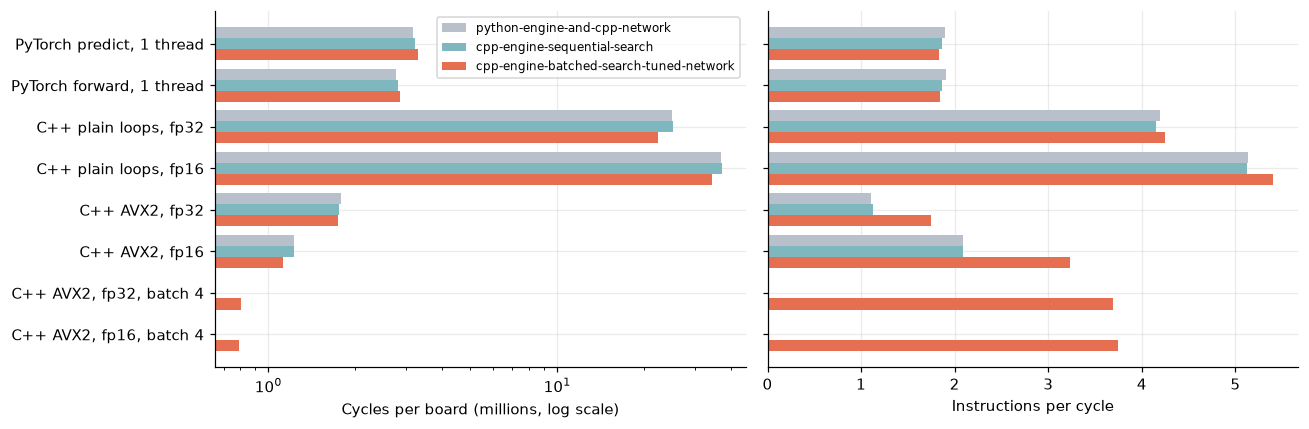

,,cycles (M),instructions (M),IPC,GHz,cache misses
variant,run,,,,,
"C++ plain loops, fp32",python-engine-and-cpp-network,24.91,104.44,4.19,4.02,8282.00
"C++ plain loops, fp16",python-engine-and-cpp-network,37.01,189.94,5.13,4.23,2248.38
"C++ AVX2, fp32",python-engine-and-cpp-network,1.78,1.97,1.11,4.06,2056.38
"C++ AVX2, fp16",python-engine-and-cpp-network,1.22,2.56,2.09,4.01,8.47
"PyTorch forward, 1 thread",python-engine-and-cpp-network,2.77,5.28,1.91,4.11,5002.62
"PyTorch predict, 1 thread",python-engine-and-cpp-network,3.17,6.01,1.89,4.23,7566.67
"C++ plain loops, fp32",cpp-engine-sequential-search,25.19,104.45,4.15,4.03,13712.32
"C++ plain loops, fp16",cpp-engine-sequential-search,37.08,189.93,5.12,4.21,2739.14
"C++ AVX2, fp32",cpp-engine-sequential-search,1.76,1.97,1.12,4.03,3372.71


In [16]:
counter_rows = {}
for run, df in networks.items():
    for variant, row in df.dropna(subset=["cycles"]).iterrows():
        counter_rows[(LABEL[variant], run)] = {
            "cycles (M)": row["cycles"] / 1e6,
            "instructions (M)": row["instructions"] / 1e6,
            "IPC": row["ipc"],
            "GHz": row["ghz"],
            "cache misses": row["cache_misses"],
        }
counters = pd.DataFrame(counter_rows).T
counters.index.names = ["variant", "run"]

cycles = counters["cycles (M)"].unstack("run")[RUNS]
ipc = counters["IPC"].unstack("run")[RUNS]
order = [LABEL[v] for v in ORDER if LABEL[v] in cycles.index]
cycles, ipc = cycles.loc[order], ipc.loc[order]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
y = np.arange(len(cycles))[::-1]
height = 0.8 / len(RUNS)
for ax, frame, label, log in ((axes[0], cycles, "Cycles per board (millions, log scale)", True), (axes[1], ipc, "Instructions per cycle", False)):
    for i, run in enumerate(RUNS):
        ax.barh(y + (len(RUNS) / 2 - i - 0.5) * height, frame[run], height=height, color=RUN_COLOR[run], label=run)
    if log:
        ax.set_xscale("log")
    ax.set_xlabel(label)
axes[0].set_yticks(y, cycles.index)
axes[0].legend(fontsize=8)
plt.tight_layout()
plt.show()

counters.round(2)

## 6. Throughput Limits

The limit of a layer is the slower of its multiply-add time at the measured peak throughput and its weight read time at the measured bandwidth. The limit of a network is the sum over layers. The latest run is shown, and batched variants are excluded.

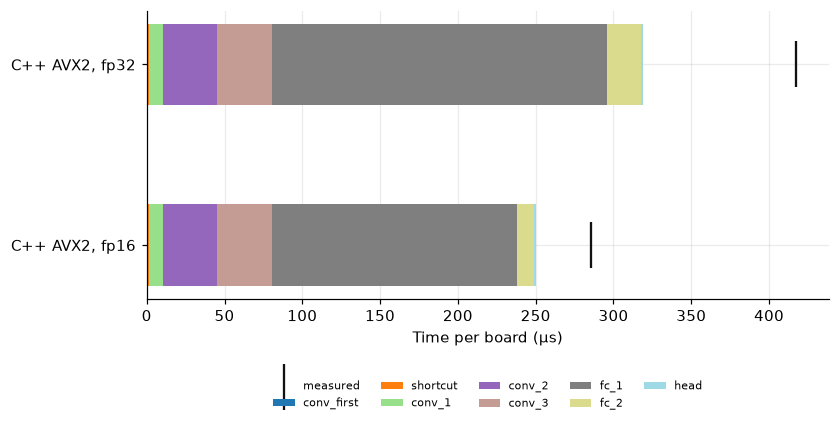

,measured (µs),limit (µs),share of limit (%),achieved GFLOP/s,achieved GB/s
"C++ AVX2, fp32",417.5,318.7,76.3,48.6,46.4
"C++ AVX2, fp16",285.8,250.2,87.5,71.0,34.8


,compute (µs),memory (µs),bound
conv_first,0.38152,0.009604,compute
shortcut,0.976692,0.024586,compute
conv_1,8.790224,0.221273,compute
conv_2,35.160894,0.88509,compute
conv_3,35.160894,0.88509,compute
fc_1,62.508256,215.092513,memory
fc_2,7.813532,22.121857,memory
head,0.503607,0.983433,memory


In [17]:
rows = {r["variant"]: r for r in json.loads((RUN_DIR[LATEST] / "network.json").read_text())["rows"]}
LAYERS = ["conv_first", "shortcut", "conv_1", "conv_2", "conv_3", "fc_1", "fc_2", "head"]
shown = ["cpp_avx2_fp32", "cpp_avx2_fp16"]

fig, ax = plt.subplots(figsize=(8, 3.4))
y = np.arange(len(shown))[::-1]
left = np.zeros(len(shown))
palette = plt.get_cmap("tab20")(np.linspace(0, 1, len(LAYERS)))
for layer, color in zip(LAYERS, palette):
    widths = np.array([max(rows[v]["layer_floors"][layer]["compute_ns"], rows[v]["layer_floors"][layer]["memory_ns"]) / 1e3 for v in shown])
    ax.barh(y, widths, left=left, color=color, label=layer, height=0.45)
    left += widths
measured = [rows[v]["median_ns"] / 1e3 for v in shown]
ax.scatter(measured, y, marker="|", s=900, color="#111", zorder=5, label="measured")
ax.set_yticks(y, [LABEL[v] for v in shown])
ax.set_xlabel("Time per board (µs)")
ax.legend(ncols=5, fontsize=7, loc="upper center", bbox_to_anchor=(0.5, -0.25), frameon=False)
plt.show()

summary = pd.DataFrame({
    v: {
        "measured (µs)": rows[v]["median_ns"] / 1e3,
        "limit (µs)": rows[v]["floor_ns"] / 1e3,
        "share of limit (%)": rows[v]["floor_share_percent"],
        "achieved GFLOP/s": rows[v]["achieved_gflops"],
        "achieved GB/s": rows[v]["achieved_gbps"],
    } for v in shown
}).T.rename(index=LABEL).round(1)
layers = pd.DataFrame({
    layer: {
        "compute (µs)": rows["cpp_avx2_fp32"]["layer_floors"][layer]["compute_ns"] / 1e3,
        "memory (µs)": rows["cpp_avx2_fp32"]["layer_floors"][layer]["memory_ns"] / 1e3,
        "bound": rows["cpp_avx2_fp32"]["layer_floors"][layer]["bound"],
    } for layer in LAYERS
}).T
display(summary)
layers

## 7. Machine Peaks

Peak throughput is the single-thread fp32 multiply-add rate. Runs that record two values report the median and the best of ten runs. Bandwidth is the best single-thread read rate over a buffer of the given size.

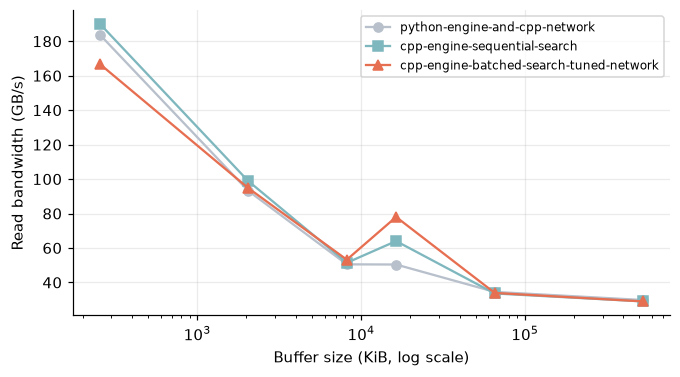

,python-engine-and-cpp-network,cpp-engine-sequential-search,cpp-engine-batched-search-tuned-network
peak fp32 (GFLOP/s),166.9,163.4,134.2
"peak fp32, best run (GFLOP/s)",NaN,NaN,154.3


In [18]:
peaks = {run: json.loads((RUN_DIR[run] / "peaks.json").read_text()) for run in RUNS}

fig, ax = plt.subplots(figsize=(7, 3.6))
for run in RUNS:
    sizes = np.array([int(k) for k in peaks[run]["read_gbps"]])
    ax.plot(sizes / 1024, list(peaks[run]["read_gbps"].values()), marker=RUN_MARKER[run], color=RUN_COLOR[run], label=run)
ax.set_xscale("log")
ax.set_xlabel("Buffer size (KiB, log scale)")
ax.set_ylabel("Read bandwidth (GB/s)")
ax.legend(fontsize=8)
plt.show()

pd.DataFrame({
    run: {
        "peak fp32 (GFLOP/s)": p["peak_gflops_fp32"],
        "peak fp32, best run (GFLOP/s)": p.get("peak_gflops_fp32_best", np.nan),
    } for run, p in peaks.items()
}).round(1)

## 8. Search Latency

Search latency is the mean time of one move search from an empty tree, with 5 boards per game phase. The batch is the number of simulations whose leaves are evaluated together.

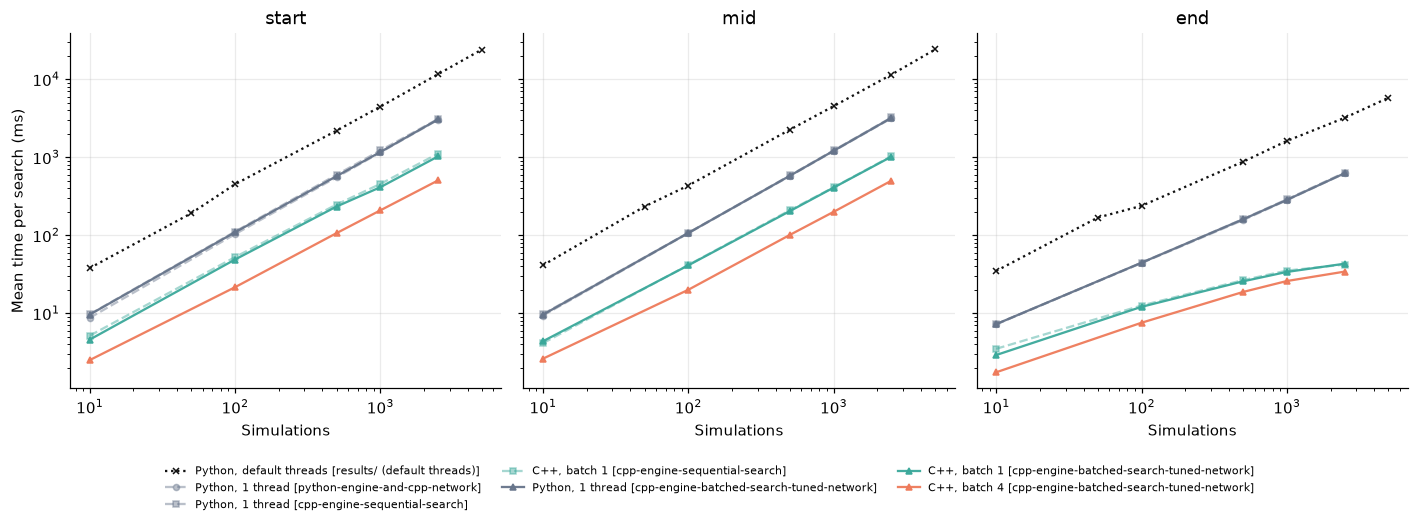

region,start,mid,end
mean ms at 500 simulations,,,
"Python, default threads [results/ (default threads)]",2194.1,2255.3,876.6
"Python, 1 thread [python-engine-and-cpp-network]",554.5,573.0,156.5
"Python, 1 thread [cpp-engine-sequential-search]",596.8,584.3,161.5
"C++, batch 1 [cpp-engine-sequential-search]",247.8,209.3,26.6
"Python, 1 thread [cpp-engine-batched-search-tuned-network]",572.7,578.9,160.1
"C++, batch 1 [cpp-engine-batched-search-tuned-network]",233.6,203.9,25.7
"C++, batch 4 [cpp-engine-batched-search-tuned-network]",106.5,101.0,18.7


In [19]:
ENGINE_LABEL = {"python_engine": "Python, 1 thread", "cpp_engine": "C++, batch 1", "cpp_batch4_engine": "C++, batch 4"}
ENGINE_COLOR = {"python_engine": "#66748a", "cpp_engine": "#3aa89a", "cpp_batch4_engine": "#ee7a5a"}

search = {(DEFAULT_THREADS, "python_engine"): pd.read_csv(RESULTS / "move_selection.csv")}
for run in RUNS:
    for folder in ENGINE_FOLDERS:
        path = RUN_DIR[run] / folder / "move_selection.csv"
        if path.exists():
            search[(run, folder)] = pd.read_csv(path)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.2), sharey=True)
for ax, region in zip(axes, REGIONS):
    for (run, folder), df in search.items():
        d = df[df.region == region]
        if run == DEFAULT_THREADS:
            ax.plot(d.sims, d.mean_ms, marker="x", ms=4, ls=":", color="#111", label=f"Python, default threads [{run}]")
        else:
            ax.plot(d.sims, d.mean_ms, marker=RUN_MARKER[run], ms=4, color=ENGINE_COLOR[folder], alpha=0.95 if run == LATEST else 0.45,
                    ls="-" if run == LATEST else "--", label=f"{ENGINE_LABEL[folder]} [{run}]")
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(region)
    ax.set_xlabel("Simulations")
axes[0].set_ylabel("Mean time per search (ms)")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, ncols=3, fontsize=7, loc="lower center", bbox_to_anchor=(0.5, -0.14), frameon=False)
plt.tight_layout()
plt.show()

SIMS = 500
table = pd.DataFrame({
    f"{ENGINE_LABEL[folder]} [{run}]": df[df.sims == SIMS].set_index("region").loc[REGIONS, "mean_ms"]
    for (run, folder), df in search.items() if run != DEFAULT_THREADS
})
table.insert(0, f"Python, default threads [{DEFAULT_THREADS}]", search[(DEFAULT_THREADS, "python_engine")].query("sims == @SIMS").set_index("region").loc[REGIONS, "mean_ms"])
table.T.round(1).rename_axis(f"mean ms at {SIMS} simulations")

## 9. Search Speedup

Speedup is the time of the reference divided by the time of the engine, for the same boards and simulation counts. The reference is the Python engine of the same run, run with one thread.

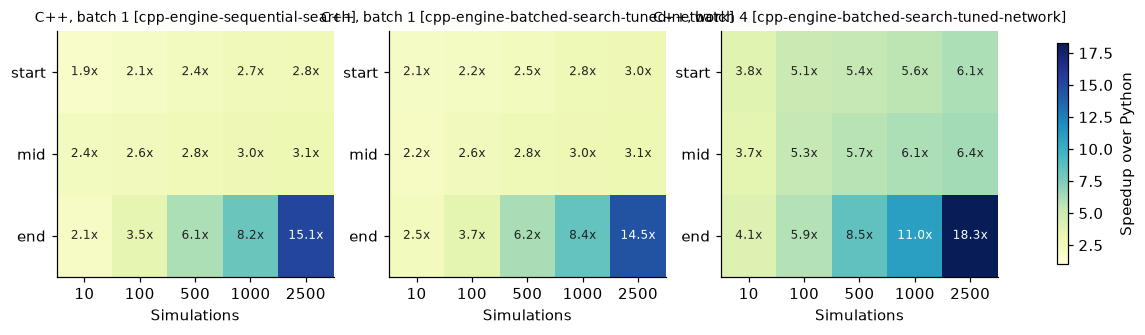

region,start,mid,end
"speedup over Python, default threads, at 2500 simulations",,,
"Python, 1 thread [python-engine-and-cpp-network]",3.8,3.6,5.1
"Python, 1 thread [cpp-engine-sequential-search]",3.8,3.5,5.0
"C++, batch 1 [cpp-engine-sequential-search]",10.5,11.1,76.0
"Python, 1 thread [cpp-engine-batched-search-tuned-network]",3.8,3.6,5.1
"C++, batch 1 [cpp-engine-batched-search-tuned-network]",11.3,11.3,74.2
"C++, batch 4 [cpp-engine-batched-search-tuned-network]",23.0,22.9,93.7


In [20]:
SHARED_SIMS = [10, 100, 500, 1000, 2500]
panels = {}
for run in RUNS:
    if (run, "python_engine") not in search:
        continue
    python_ms = search[(run, "python_engine")].pivot(index="region", columns="sims", values="mean_ms").loc[REGIONS, SHARED_SIMS]
    for folder in ("cpp_engine", "cpp_batch4_engine"):
        if (run, folder) in search:
            cpp_ms = search[(run, folder)].pivot(index="region", columns="sims", values="mean_ms").loc[REGIONS, SHARED_SIMS]
            panels[f"{ENGINE_LABEL[folder]} [{run}]"] = python_ms / cpp_ms

fig, axes = plt.subplots(1, len(panels), figsize=(4.6 * len(panels), 2.9), squeeze=False)
vmax = max(p.values.max() for p in panels.values())
for ax, (name, ratio) in zip(axes[0], panels.items()):
    image = ax.imshow(ratio.values, cmap="YlGnBu", vmin=1, vmax=vmax, aspect="auto")
    ax.set_xticks(range(len(ratio.columns)), ratio.columns)
    ax.set_yticks(range(len(ratio.index)), ratio.index)
    ax.set_title(name, fontsize=9)
    ax.set_xlabel("Simulations")
    ax.grid(False)
    for i in range(ratio.shape[0]):
        for j in range(ratio.shape[1]):
            value = ratio.values[i, j]
            ax.text(j, i, f"{value:.1f}x", ha="center", va="center", fontsize=8, color="white" if value > vmax * 0.6 else "#222")
fig.colorbar(image, ax=axes[0].tolist(), label="Speedup over Python", shrink=0.9)
plt.show()

reference = search[(DEFAULT_THREADS, "python_engine")].query("sims == 2500").set_index("region").loc[REGIONS, "mean_ms"]
at_2500 = pd.DataFrame({
    f"{ENGINE_LABEL[folder]} [{run}]": reference / df.query("sims == 2500").set_index("region").loc[REGIONS, "mean_ms"]
    for (run, folder), df in search.items() if run != DEFAULT_THREADS
}).T.round(1)
at_2500.rename_axis("speedup over Python, default threads, at 2500 simulations")

## 10. Board Rules

Rules are timed per call. Perft counts the leaf positions of the game tree from the initial position at depth 10.

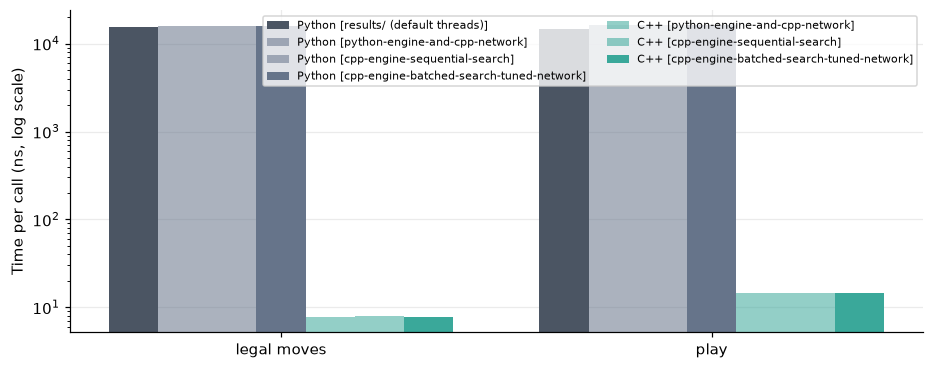

,legal moves,play
Python [results/ (default threads)],15455.0,14836.7
Python [python-engine-and-cpp-network],15721.7,16079.6
Python [cpp-engine-sequential-search],16046.0,16366.1
Python [cpp-engine-batched-search-tuned-network],15690.6,16110.8
C++ [python-engine-and-cpp-network],7.7,14.4
C++ [cpp-engine-sequential-search],7.9,14.7
C++ [cpp-engine-batched-search-tuned-network],7.7,14.5


,python-engine-and-cpp-network,cpp-engine-sequential-search,cpp-engine-batched-search-tuned-network
perft leaves (depth 10),24571284.0,24571284.0,24571284.0
perft throughput (million leaves/s),49.3,47.9,48.2


In [21]:
rules = {run: json.loads((RUN_DIR[run] / "rules.json").read_text()) for run in RUNS}
python_rules = {
    run: pd.read_csv(RUN_DIR[run] / "python_engine" / "board_logic.csv").groupby("operation")["mean_ms"].mean() * 1e6
    for run in RUNS if (RUN_DIR[run] / "python_engine" / "board_logic.csv").exists()
}
default_rules = pd.read_csv(RESULTS / "board_logic.csv").groupby("operation")["mean_ms"].mean() * 1e6

OPERATIONS = {"legal moves": ("get_valid_moves", "legal_moves_ns"), "play": ("get_next_state", "play_ns")}
frame = {}
frame[f"Python [{DEFAULT_THREADS}]"] = {op: default_rules[py] for op, (py, _) in OPERATIONS.items()}
for run in RUNS:
    frame[f"Python [{run}]"] = {op: python_rules[run][py] for op, (py, _) in OPERATIONS.items()}
for run in RUNS:
    frame[f"C++ [{run}]"] = {op: float(np.median(rules[run][cpp])) for op, (_, cpp) in OPERATIONS.items()}
comparison = pd.DataFrame(frame)

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(comparison))
width = 0.8 / len(comparison.columns)
for i, column in enumerate(comparison.columns):
    color = "#4b5563" if DEFAULT_THREADS in column else ("#66748a" if column.startswith("Python") else "#3aa89a")
    ax.bar(x + (i - (len(comparison.columns) - 1) / 2) * width, comparison[column], width=width, color=color,
           alpha=1.0 if LATEST in column or DEFAULT_THREADS in column else 0.55, label=column)
ax.set_xticks(x, comparison.index)
ax.set_yscale("log")
ax.set_ylabel("Time per call (ns, log scale)")
ax.legend(fontsize=7, ncols=2)
plt.show()

display(comparison.T.round(1))
pd.DataFrame({
    run: {
        "perft leaves (depth 10)": r["perft_leaves"],
        "perft throughput (million leaves/s)": r["perft_leaves_per_second_median"] / 1e6,
    } for run, r in rules.items()
}).round(1)

## 11. Run Comparison

The table lists the speedup of each variant over PyTorch predict with 1 thread in the same run.

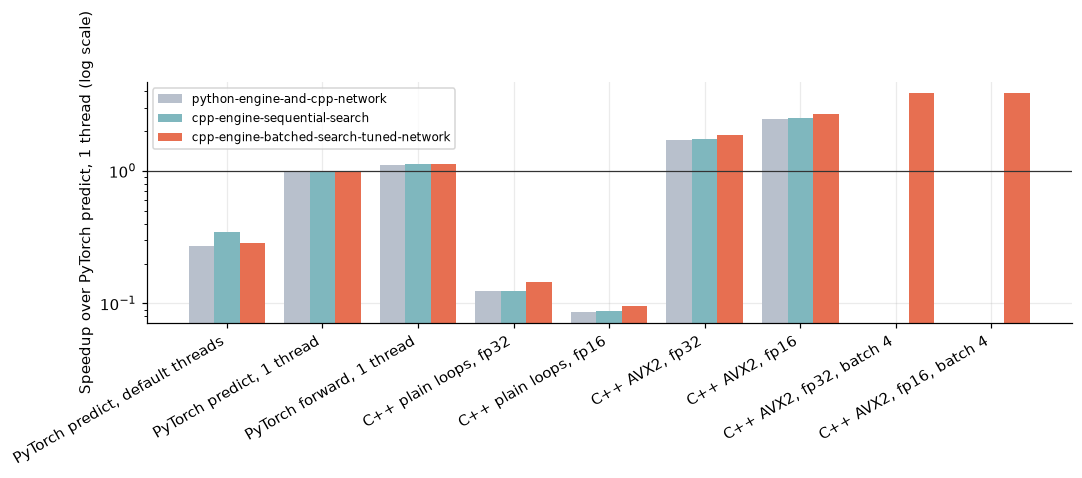

,python-engine-and-cpp-network,cpp-engine-sequential-search,cpp-engine-batched-search-tuned-network
variant,,,
"PyTorch predict, default threads",0.27,0.35,0.28
"PyTorch predict, 1 thread",1.00,1.00,1.00
"PyTorch forward, 1 thread",1.11,1.12,1.13
"C++ plain loops, fp32",0.12,0.13,0.14
"C++ plain loops, fp16",0.09,0.09,0.10
"C++ AVX2, fp32",1.72,1.75,1.85
"C++ AVX2, fp16",2.47,2.50,2.70
"C++ AVX2, fp32, batch 4",NaN,NaN,3.85
"C++ AVX2, fp16, batch 4",NaN,NaN,3.86


In [22]:
speedups = pd.DataFrame({
    run: df["median_ns"].loc["torch_predict_1thread"] / df["median_ns"] for run, df in networks.items()
}).reindex(ORDER).dropna(how="all")

fig, ax = plt.subplots(figsize=(10, 3.8))
x = np.arange(len(speedups))
width = 0.8 / len(RUNS)
for i, run in enumerate(RUNS):
    ax.bar(x + (i - (len(RUNS) - 1) / 2) * width, speedups[run], width=width, color=RUN_COLOR[run], label=run)
ax.axhline(1, color="#333", lw=0.8)
ax.set_xticks(x, [LABEL[v] for v in speedups.index], rotation=30, ha="right")
ax.set_yscale("log")
ax.set_ylabel("Speedup over PyTorch predict, 1 thread (log scale)")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

speedups.rename(index=LABEL).round(2)